In [1]:
# bài 3


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [42]:
X = np.array([2.5, 0.5, 2.2, 1.9, 3.1, 2.3, 2.0, 1.0, 1.5, 1.1])
Y = np.array([2.4, 0.7, 2.9, 2.2, 3.0, 2.7, 1.6, 1.1, 1.6, 0.9])
data = np.column_stack((X, Y))
data

array([[2.5, 2.4],
       [0.5, 0.7],
       [2.2, 2.9],
       [1.9, 2.2],
       [3.1, 3. ],
       [2.3, 2.7],
       [2. , 1.6],
       [1. , 1.1],
       [1.5, 1.6],
       [1.1, 0.9]])

In [46]:
mean = data.mean(axis=0)
data_mean = data - mean

cov_matrix = np.cov(data_mean,rowvar= False)
giaTriRieng, vectorRieng = np.linalg.eig(cov_matrix)

max_indx = np.argmax(giaTriRieng)
v_main = vector_Rieng[:,max_indx]

data_1d =  data_chuanHoa @ v_main

data_back = np.outer(data_1d,v_main) + mean


print('Ma trận hiệp phương sai:\n', cov_matrix)
print('Giá trị riêng:\n', giaTriRieng)
print('Vector riêng:\n', vector_Rieng)
print('Dữ liệu 1 chiều mới:\n', data_1d)

# Bảng so sánh dữ liệu gốc và dữ liệu tái tạo
df_result = pd.DataFrame(np.hstack([data, data_back]), columns=["x", "y", "x_rec", "y_rec"])
print("\nSo sánh dữ liệu gốc và khôi phục:")
print(df_result)



Ma trận hiệp phương sai:
 [[0.61655556 0.61544444]
 [0.61544444 0.71655556]]
Giá trị riêng:
 [0.0490834  1.28402771]
Vector riêng:
 [[-0.73517866 -0.6778734 ]
 [ 0.6778734  -0.73517866]]
Dữ liệu 1 chiều mới:
 [-0.82797019  1.77758033 -0.99219749 -0.27421042 -1.67580142 -0.9129491
  0.09910944  1.14457216  0.43804614  1.22382056]

So sánh dữ liệu gốc và khôi phục:
     x    y     x_rec     y_rec
0  2.5  2.4  2.371259  2.518706
1  0.5  0.7  0.605026  0.603161
2  2.2  2.9  2.482584  2.639442
3  1.9  2.2  1.995880  2.111594
4  3.1  3.0  2.945981  3.142013
5  2.3  2.7  2.428864  2.581181
6  2.0  1.6  1.742816  1.837137
7  1.0  1.1  1.034125  1.068535
8  1.5  1.6  1.513060  1.587958
9  1.1  0.9  0.980405  1.010273


tỉ lệ tính phương sai tích lũy:  [0.36905718 0.22214214]
độ chính xác trên tập train:  0.9596774193548387
độ chính xác trên tập test:  0.9444444444444444


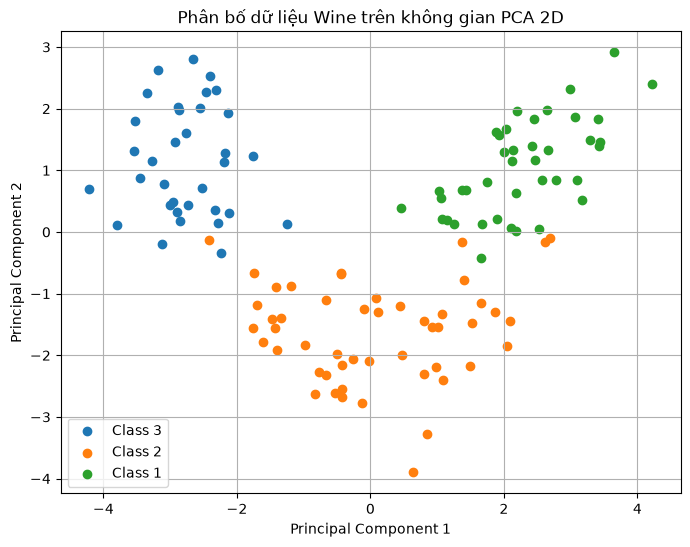

In [58]:
## bai2:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

cols = ["Class", "Alcohol", "Malic acid", "Ash", "Alcalinity of ash", "Magnesium",
        "Total phenols", "Flavanoids", "Nonflavanoid phenols", "Proanthocyanins",
        "Color intensity", "Hue", "OD280/OD315", "Proline"]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
df = pd.read_csv(url, header=None,names = cols)

X = df.iloc[:,1:]
y = df.iloc[:,0]


X_train,X_test,y_train,y_test = train_test_split(X,y,test_size= 0.3,random_state= 42)

#chuẩn hóa
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.fit_transform(X_test)



#áp dụng PCA để giảm chiều dữ liệu:



pca = PCA(n_components= 2)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.fit_transform(X_test_std)

print('tỉ lệ tính phương sai tích lũy: ',pca.explained_variance_ratio_)

clf = LogisticRegression()
clf.fit(X_train_pca,y_train)

print('độ chính xác trên tập train: ',clf.score(X_train_pca,y_train))
print('độ chính xác trên tập test: ',clf.score(X_test_pca,y_test))


# 6. Trực quan hóa phân bố dữ liệu sau khi giảm chiều
plt.figure(figsize=(8, 6))
for label in y_train.unique():
    plt.scatter(
        X_train_pca[y_train == label, 0],
        X_train_pca[y_train == label, 1],
        label=f'Class {label}'
    )
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Phân bố dữ liệu Wine trên không gian PCA 2D')
plt.legend()
plt.grid(True)
plt.show()

In [62]:
#câu 2:
A = np.array([[3,2,2],[2,3,-2]])

U, s, VT = np.linalg.svd(A)

sigma = np.zeros(A.shape)
sigma[:2,:2] = np.diag(s)

A_pinv = np.linalg.pinv(A)

print("Ma trận U:\n", U)
print("Các giá trị đơn lẻ (Singular values):", s)
print("Ma trận sigma:\n", sigma)
print("Ma trận Vt:\n", VT)
print("Ma trận giả nghịch đảo A+:\n", A_pinv)

Ma trận U:
 [[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]
Các giá trị đơn lẻ (Singular values): [5. 3.]
Ma trận sigma:
 [[5. 0. 0.]
 [0. 3. 0.]]
Ma trận Vt:
 [[ 7.07106781e-01  7.07106781e-01  3.67439059e-16]
 [-2.35702260e-01  2.35702260e-01 -9.42809042e-01]
 [-6.66666667e-01  6.66666667e-01  3.33333333e-01]]
Ma trận giả nghịch đảo A+:
 [[ 0.15555556  0.04444444]
 [ 0.04444444  0.15555556]
 [ 0.22222222 -0.22222222]]


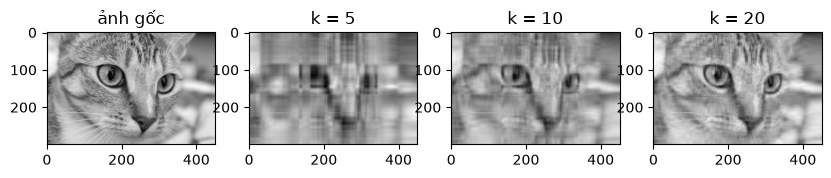

In [70]:
# nén ảnh
from skimage import data
from skimage.color import rgb2gray

img = data.chelsea()
img_gray = rgb2gray(img)

U,s,VT = np.linalg.svd(img_gray,full_matrices= False)

ks = [5,10,20]

plt.figure(figsize=(10,5))
plt.subplot(1,4,1)
plt.imshow(img_gray,cmap = 'gray')
plt.title('ảnh gốc')
i=2
for k in ks:
    image = np.dot(U[:,:k] * s[:k], VT[:k,:])
    plt.subplot(1,4,i)
    plt.imshow(image,cmap = 'gray')
    plt.title(f'k = {k}')
    i +=1
plt.show()
                   
                   


CÂU 3 (2.5 điểm): Content-Based Filtering & User-User Collaborative Filtering(1.5 điểm)  
Content-Based Filtering:Giả sử mỗi môn học được mô tả bằng đặc trưng TF-IDF (hoặc vector thuộc tính môn học).Xây dựng mô hình Ridge Regression cho từng sinh viên dựa trên các môn đã có điểm.Dự đoán điểm cho các môn còn thiếu bằng công thức:$$\hat{Y} = \text{TFIDF} \cdot W + b$$  
Đánh giá mô hình bằng chỉ số RMSE (Root Mean Squared Error) trên các ô dữ liệu đã biết.(1.0 điểm)   
User-User Collaborative Filtering:Tính độ tương đồng Cosine (Cosine Similarity) giữa các sinh viên dựa trên các môn học đã có điểm chung.  
Tìm top $K=2$ sinh viên tương đồng nhất với SV 1 để dự đoán điểm còn thiếu của SV 1 ở môn Mạng máy tính (Net).

In [71]:
tfidf_features = np.array([
    [0.8, 0.1, 0.1],  # Math
    [0.1, 0.9, 0.2],  # Prog
    [0.2, 0.7, 0.8],  # DB
    [0.3, 0.6, 0.7]   # Net
])
#điểm số
R = np.array([
    [8.0, 9.0, 7.5, np.nan],
    [5.0, np.nan, 6.0, 5.5],
    [np.nan, 8.5, 9.0, 8.0],
    [7.0, 6.5, np.nan, 7.0],
    [9.0, 9.5, 8.0, 8.5]
])
#dự đoán điểm sinh viên 1
diemDaBiet = [0,1,2]
X_train_u1 = tfidf_features[diemDaBiet]
y_train_u1 = R[0,diemDaBiet]

from sklearn.linear_model import Ridge

r = Ridge()
r.fit(X_train_u1,y_train_u1)
#dự đoán:
pred_u1 = r.predict([tfidf_features[3]])[0]
print('điểm dự đoán u1: ',pred_u1)

điểm dự đoán u1:  8.071331773816246


In [73]:
def cosine_similarity_masked(u1, u2):
    # Chỉ tính Cosine similarity trên các môn mà cả 2 SV đều đã đánh giá
    mask = ~np.isnan(u1) & ~np.isnan(u2)
    if not np.any(mask):
        return 0.0
    dot_prod = np.dot(u1[mask], u2[mask])
    norm = np.linalg.norm(u1[mask]) * np.linalg.norm(u2[mask])
    return dot_prod / norm if norm != 0 else 0.0

# Tính tương đồng giữa SV 1 với các SV khác
sims = [cosine_similarity_masked(R[0], R[u]) for u in range(1, 5)]
print("Độ tương đồng của SV1 với [SV2, SV3, SV4, SV5]:", np.round(sims, 3))

# Dự đoán điểm môn Net cho SV1 bằng trung bình có trọng số từ Top K=2 người tương đồng
# SV có điểm môn Net: SV2(idx 1), SV3(idx 2), SV4(idx 3), SV5(idx 4)
top_k_users = [2, 4]  # Giả sử SV3 và SV5 có độ tương đồng cao nhất
weights = [sims[1], sims[3]]
ratings = [R[2, 3], R[4, 3]]

pred_cf = np.dot(weights, ratings) / np.sum(weights)
print(f"Điểm môn Net dự đoán cho SV 1 (User-User CF): {pred_cf:.2f}")

Độ tương đồng của SV1 với [SV2, SV3, SV4, SV5]: [0.992 0.993 0.995 1.   ]
Điểm môn Net dự đoán cho SV 1 (User-User CF): 8.25


In [75]:
# câu 4
import numpy as np

np.random.seed(42)
n_users, n_items = R.shape
K = 2

X = np.random.rand(n_items, K)
W = np.random.rand(n_users, K)

lr = 0.01   # Learning rate
lam = 0.1   # Regularization factor
epochs = 200

# Vòng lặp cập nhật Gradient Descent (5.4)
for epoch in range(epochs):
    for u in range(n_users):
        for i in range(n_items):
            if not np.isnan(R[u, i]):
                # Sai số e_ui = R_ui - x_i * w_u^T
                e_ui = R[u, i] - np.dot(X[i], W[u])
                
                # Cập nhật Vector ẩn
                X[i] += lr * (2 * e_ui * W[u] - lam * X[i])
                W[u] += lr * (2 * e_ui * X[i] - lam * W[u])

# Dự đoán toàn bộ ma trận (5.5)
R_hat = np.dot(W, X.T)

print("Ma trận điểm dự đoán hoàn chỉnh (Matrix Factorization):\n", np.round(R_hat, 2))

Ma trận điểm dự đoán hoàn chỉnh (Matrix Factorization):
 [[7.94 8.53 7.84 7.81]
 [5.4  6.07 5.8  5.32]
 [8.03 8.95 8.48 7.91]
 [6.92 6.74 5.66 6.78]
 [8.77 9.11 8.14 8.62]]
